# EXP-001 직거래 EDA

데이터: SYN-001 (`data/processed/rh_trade_clean.parquet`). 읽기만 한다.

## 4-1. 데이터 개요
이 셀에서 확인하는 질문: 전체 건수, 직거래 건수와 비율, dealingGbn·buyerGbn·slerGbn의 고유값과 건수는 어떠한가?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.family'] = 'Noto Sans CJK KR'
mpl.rcParams['axes.unicode_minus'] = False

df = pd.read_parquet('../data/processed/rh_trade_clean.parquet')

total_n = len(df)
direct_n = int(df['direct_flag'].sum())
direct_ratio = direct_n / total_n

print(f"전체 건수: {total_n:,}")
print(f"직거래 건수: {direct_n:,} ({direct_ratio:.1%})")

print("\ndealingGbn 고유값:")
print(df['dealingGbn'].value_counts())
print("\nbuyerGbn 고유값:")
print(df['buyerGbn'].value_counts())
print("\nslerGbn 고유값:")
print(df['slerGbn'].value_counts())


전체 건수: 69,371
직거래 건수: 11,763 (17.0%)

dealingGbn 고유값:
dealingGbn
중개거래    57608
직거래     11763
Name: count, dtype: int64

buyerGbn 고유값:
buyerGbn
개인      64709
공공기관     2516
법인       1649
기타        497
Name: count, dtype: int64

slerGbn 고유값:
slerGbn
개인      63237
법인       5978
기타        128
공공기관       28
Name: count, dtype: int64


## 4-2. 직거래 비율 분해
이 셀에서 확인하는 질문: 직거래 비율이 구·월·주택유형·연식·면적·지하여부·매도매수자 구분별로 어떻게 다른가?

연식 구간: 신축(0~2년) / 3~10년 / 11~20년 / 21년 이상 (거래연도-건축년도 기준). 면적 구간: ~30㎡ / 30~45㎡ / 45~60㎡ / 60㎡~ (excluUseAr 분위수 기반).

In [2]:
lawd = pd.read_csv('../docs/seoul_lawd_cd.csv', dtype={'LAWD_CD': str}).set_index('LAWD_CD')['gu_name']
df['gu_name'] = df['sggCd'].astype(str).map(lawd)

df['age_years'] = df['dealYear'].astype(int) - df['buildYear'].astype(int)
age_bins = [-np.inf, 2, 10, 20, np.inf]
age_labels = ['신축(0~2년)', '3~10년', '11~20년', '21년 이상']
df['age_bucket'] = pd.cut(df['age_years'], bins=age_bins, labels=age_labels)

area_bins = [0, 30, 45, 60, np.inf]
area_labels = ['~30㎡', '30~45㎡', '45~60㎡', '60㎡~']
df['area_bucket'] = pd.cut(df['excluUseAr'], bins=area_bins, labels=area_labels)

df['ym'] = df['dealYear'].astype(str) + df['dealMonth'].astype(str).str.zfill(2)

def direct_ratio_table(group_col):
    t = df.groupby(group_col, observed=True)['direct_flag'].agg(['sum', 'count'])
    t['ratio'] = t['sum'] / t['count']
    return t.rename(columns={'sum': '직거래건수', 'count': '전체건수', 'ratio': '직거래비율'})

by_gu = direct_ratio_table('gu_name')
by_month = direct_ratio_table('ym')
by_house = direct_ratio_table('houseType')
by_age = direct_ratio_table('age_bucket')
by_area = direct_ratio_table('area_bucket')
by_basement = direct_ratio_table('basement_flag')

cross = pd.crosstab([df['slerGbn'], df['buyerGbn']], df['direct_flag'])
cross.columns = ['중개거래', '직거래']
cross['직거래비율'] = cross['직거래'] / (cross['중개거래'] + cross['직거래'])

print("구별 직거래 비율"); print(by_gu)
print("\n월별 직거래 비율"); print(by_month)
print("\n주택유형별 직거래 비율"); print(by_house)
print("\n연식구간별 직거래 비율"); print(by_age)
print("\n면적구간별 직거래 비율"); print(by_area)
print("\n지하여부별 직거래 비율"); print(by_basement)
print("\n매도자x매수자 구분 교차표"); print(cross)


구별 직거래 비율
         직거래건수  전체건수     직거래비율
gu_name                       
강남구        221  1966  0.112411
강동구        669  3528  0.189626
강북구        764  2784  0.274425
강서구        917  5217  0.175772
관악구        546  3403  0.160447
광진구        632  4428  0.142728
구로구        267  2061  0.129549
금천구        412  1819  0.226498
노원구        246  1103  0.223028
도봉구        598  2151  0.278010
동대문구       417  1578  0.264259
동작구        642  4013  0.159980
마포구        472  3047  0.154906
서대문구       351  1949  0.180092
서초구        311  2563  0.121342
성동구        243  1186  0.204890
성북구        463  2806  0.165004
송파구        757  5532  0.136840
양천구        575  4030  0.142680
영등포구       301  1715  0.175510
용산구        170  1799  0.094497
은평구        777  5631  0.137986
종로구        157   989  0.158746
중구          50   671  0.074516
중랑구        805  3402  0.236626

월별 직거래 비율
        직거래건수  전체건수     직거래비율
ym                           
202411    527  2032  0.259350
202412    549  1789  0.306875
202501    472  1583  0

## 4-3. ㎡당 가격 원분포
이 셀에서 확인하는 질문: 직거래와 중개거래의 ㎡당 가격 원분포(히스토그램, 분위수)는 어떻게 다른가?

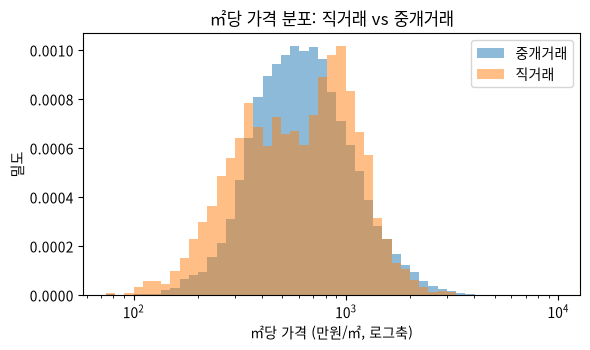

            중개거래          직거래
5%    350.877193   291.774918
25%   570.412776   587.870367
50%   821.624487   894.824708
75%  1205.259237  1190.966387
95%  2180.232558  1871.988845


In [3]:
direct_price = df.loc[df['direct_flag']==1, 'price_per_m2']
brokered_price = df.loc[df['direct_flag']==0, 'price_per_m2']

fig, ax = plt.subplots(figsize=(6,3.6), dpi=100)
bins = np.logspace(np.log10(df['price_per_m2'].min()), np.log10(df['price_per_m2'].max()), 50)
ax.hist(brokered_price, bins=bins, alpha=0.5, label='중개거래', density=True)
ax.hist(direct_price, bins=bins, alpha=0.5, label='직거래', density=True)
ax.set_xscale('log')
ax.set_xlabel('㎡당 가격 (만원/㎡, 로그축)')
ax.set_ylabel('밀도')
ax.set_title('㎡당 가격 분포: 직거래 vs 중개거래')
ax.legend()
fig.tight_layout()
fig.savefig('../results/figures/exp001_price_hist.png', dpi=100)
plt.show()
plt.close(fig)

q_levels = [0.05, 0.25, 0.5, 0.75, 0.95]
quantile_table = pd.DataFrame({
    '중개거래': brokered_price.quantile(q_levels).values,
    '직거래': direct_price.quantile(q_levels).values,
}, index=['5%', '25%', '50%', '75%', '95%'])
print(quantile_table)


## 4-4. 조건 보정 비교
이 셀에서 확인하는 질문: 법정동×연식×면적 셀로 보정한 상대가격 기준으로 직거래와 중개거래가 다른가? (outlier 포함/제외 두 버전)

셀 정의: 법정동(sggCd+umdNm) × 연식구간 × 면적구간. 중개거래 5건 미만 셀은 제외. 상대가격 = 거래 ㎡당가격 ÷ 셀의 중개거래 ㎡당가격 중앙값.

유효 셀(중개거래 5건 이상)에 포함된 직거래: 8,576 / 11,763 (72.9%)

outlier 포함
     구분     건수       중앙값       IQR
0   직거래   8576  0.911744  0.401715
1  중개거래  55658  1.000000  0.289281

outlier 제외
     구분     건수       중앙값       IQR
0   직거래   8285  0.920566  0.389986
1  중개거래  54634  1.000000  0.283394


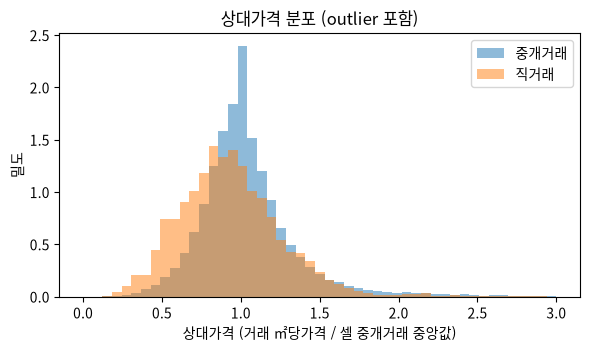

In [4]:
df['dong_code'] = df['sggCd'].astype(str) + '_' + df['umdNm'].str.strip()
df['cell_id'] = df['dong_code'] + '|' + df['age_bucket'].astype(str) + '|' + df['area_bucket'].astype(str)

brokered_mask = df['direct_flag'] == 0
cell_median = df.loc[brokered_mask].groupby('cell_id')['price_per_m2'].median()
cell_count = df.loc[brokered_mask].groupby('cell_id')['price_per_m2'].count()
valid_cells = cell_count[cell_count >= 5].index

valid_all = df[df['cell_id'].isin(valid_cells)].copy()
valid_all['cell_median'] = valid_all['cell_id'].map(cell_median)
valid_all['rel_price'] = valid_all['price_per_m2'] / valid_all['cell_median']

direct_total = int(df['direct_flag'].sum())
direct_in_valid = int((valid_all['direct_flag'] == 1).sum())
coverage = direct_in_valid / direct_total
print(f"유효 셀(중개거래 5건 이상)에 포함된 직거래: {direct_in_valid:,} / {direct_total:,} ({coverage:.1%})")
if coverage < 0.5:
    print("[멈춤 지점] 유효 셀 포함 직거래 비율이 50% 미만입니다. 셀 정의 변경 여부를 사용자가 결정해야 합니다.")

def summarize(data):
    d = data.loc[data['direct_flag']==1, 'rel_price']
    b = data.loc[data['direct_flag']==0, 'rel_price']
    return pd.DataFrame({
        '구분': ['직거래', '중개거래'],
        '건수': [len(d), len(b)],
        '중앙값': [d.median(), b.median()],
        'IQR': [d.quantile(.75)-d.quantile(.25), b.quantile(.75)-b.quantile(.25)],
    })

summary_incl = summarize(valid_all)
print("\noutlier 포함"); print(summary_incl)

valid_excl = valid_all[valid_all['outlier_flag']==0]
summary_excl = summarize(valid_excl)
print("\noutlier 제외"); print(summary_excl)

fig, ax = plt.subplots(figsize=(6,3.6), dpi=100)
bins = np.linspace(0, 3, 50)
ax.hist(valid_all.loc[valid_all['direct_flag']==0,'rel_price'], bins=bins, alpha=0.5, label='중개거래', density=True)
ax.hist(valid_all.loc[valid_all['direct_flag']==1,'rel_price'], bins=bins, alpha=0.5, label='직거래', density=True)
ax.set_xlabel('상대가격 (거래 ㎡당가격 / 셀 중개거래 중앙값)')
ax.set_ylabel('밀도')
ax.set_title('상대가격 분포 (outlier 포함)')
ax.legend()
fig.tight_layout()
fig.savefig('../results/figures/exp001_relprice_hist.png', dpi=100)
plt.show()
plt.close(fig)


## 4-5. 직거래 하위 유형 분리 (규칙 기반)
이 셀에서 확인하는 질문: 직거래를 분양의심/저가의심/기타로 나누면 유형별 특성이 어떻게 다른가?

정의:
- 분양 의심: 매도자 법인(slerGbn=='법인') + 신축(age_bucket=='신축(0~2년)')
- 저가 의심: 매도자·매수자 모두 개인(slerGbn=='개인' and buyerGbn=='개인') + 상대가격(rel_price) < 0.7
- 기타 직거래: 위 두 조건에 해당하지 않는 나머지 직거래
(4-4의 유효 셀(valid_all)에 포함된 직거래만 대상으로 함, rel_price 필요)

In [5]:
direct_valid = valid_all[valid_all['direct_flag']==1].copy()

def classify(row):
    if row['slerGbn'] == '법인' and row['age_bucket'] == '신축(0~2년)':
        return '분양 의심'
    if row['slerGbn'] == '개인' and row['buyerGbn'] == '개인' and row['rel_price'] < 0.7:
        return '저가 의심'
    return '기타 직거래'

direct_valid['subtype'] = direct_valid.apply(classify, axis=1)

subtype_summary = direct_valid.groupby('subtype').agg(
    건수=('subtype', 'size'),
    상대가격_중앙값=('rel_price', 'median'),
    상대가격_25=('rel_price', lambda s: s.quantile(.25)),
    상대가격_75=('rel_price', lambda s: s.quantile(.75)),
)
subtype_summary['IQR'] = subtype_summary['상대가격_75'] - subtype_summary['상대가격_25']
subtype_summary['비율'] = subtype_summary['건수'] / subtype_summary['건수'].sum()
print(subtype_summary)


           건수  상대가격_중앙값   상대가격_25   상대가격_75       IQR        비율
subtype                                                        
기타 직거래   6505  0.982647  0.832063  1.182157  0.350094  0.758512
분양 의심     548  0.907295  0.791525  1.055372  0.263847  0.063899
저가 의심    1523  0.567165  0.467052  0.634796  0.167745  0.177589


## 4-6. 같은 지번 반복 거래
이 셀에서 확인하는 질문: 같은 지번에서 직거래가 여러 번 발생한 경우는 얼마나 있으며, 상위 10개 지번은 어디인가(지번은 앞자리만 남기고 마스킹)?

In [6]:
direct_df = df[df['direct_flag']==1].copy()
direct_df['parcel_key'] = direct_df['sggCd'].astype(str) + '_' + direct_df['umdNm'].str.strip() + '_' + direct_df['jibun'].str.strip()

parcel_counts = direct_df.groupby('parcel_key').size().sort_values(ascending=False)
repeated = parcel_counts[parcel_counts >= 2]
print(f"직거래 2회 이상 발생한 지번 수: {len(repeated)}")
print(f"해당 지번에서 발생한 직거래 총 건수: {int(repeated.sum())}")

def mask_jibun(key):
    parts = key.split('_')
    jibun = parts[-1]
    masked = jibun[0] + '*' * (len(jibun) - 1) if len(jibun) > 1 else jibun
    return '_'.join(parts[:-1] + [masked])

top10 = repeated.head(10).rename_axis('지번키').reset_index(name='직거래건수')
top10['지번(마스킹)'] = top10['지번키'].apply(mask_jibun)
top10 = top10[['지번(마스킹)', '직거래건수']]
print(top10)


직거래 2회 이상 발생한 지번 수: 1264
해당 지번에서 발생한 직거래 총 건수: 7433
             지번(마스킹)  직거래건수
0     11230_청량리동_2**     94
1    11440_염리동_2****     54
2  11200_성수동2가_2****     54
3      11305_수유동_7**     49
4    11410_북아현동_1***     47
5   11560_양평동6가_9***     45
6   11260_면목동_2*****     44
7       11710_오금동_7*     42
8   11305_수유동_4*****     39
9    11305_우이동_1****     37


## 4-7. 기각 기준 판정
이 셀에서 확인하는 질문: 기각 기준 1, 2가 실제로 충족되는가?

In [7]:
direct_median = float(summary_incl.loc[summary_incl['구분']=='직거래', '중앙값'].iloc[0])
direct_iqr = float(summary_incl.loc[summary_incl['구분']=='직거래', 'IQR'].iloc[0])
brokered_iqr = float(summary_incl.loc[summary_incl['구분']=='중개거래', 'IQR'].iloc[0])
iqr_ratio = direct_iqr / brokered_iqr

criterion1 = (direct_median <= 0.95) or (direct_median >= 1.05)
criterion2 = iqr_ratio >= 1.5

verdict_table = pd.DataFrame({
    '기준': [
        '1. 직거래 상대가격 중앙값이 1.00에서 5% 이상 벗어남(<=0.95 또는 >=1.05)',
        '2. 직거래 IQR이 중개거래 IQR의 1.5배 이상',
    ],
    '실제값': [
        f"중앙값={direct_median:.3f}",
        f"직거래IQR={direct_iqr:.3f}, 중개거래IQR={brokered_iqr:.3f}, 비율={iqr_ratio:.2f}배",
    ],
    '충족 여부': [criterion1, criterion2],
})
print(verdict_table)

if criterion1 or criterion2:
    final_verdict = '직거래 기본 제외'
else:
    final_verdict = '직거래 포함'

print(f"\n최종 판정: {final_verdict}")


                                                  기준  \
0  1. 직거래 상대가격 중앙값이 1.00에서 5% 이상 벗어남(<=0.95 또는 >=...   
1                      2. 직거래 IQR이 중개거래 IQR의 1.5배 이상   

                                     실제값  충족 여부  
0                              중앙값=0.912   True  
1  직거래IQR=0.402, 중개거래IQR=0.289, 비율=1.39배  False  

최종 판정: 직거래 기본 제외


## 4-8. 요약

In [8]:
print("요약:")
print(f"1. 직거래 비율은 전체 {direct_ratio:.1%}이며, 법정동x연식x면적 보정 후 상대가격 중앙값은 {direct_median:.3f}(기준 1.00)이다.")
print(f"2. 직거래 상대가격 IQR은 중개거래의 {iqr_ratio:.2f}배이다.")
print(f"3. 기각 기준 결과: {final_verdict} (유효 셀 포함 직거래 비율 {coverage:.1%})")


요약:
1. 직거래 비율은 전체 17.0%이며, 법정동x연식x면적 보정 후 상대가격 중앙값은 0.912(기준 1.00)이다.
2. 직거래 상대가격 IQR은 중개거래의 1.39배이다.
3. 기각 기준 결과: 직거래 기본 제외 (유효 셀 포함 직거래 비율 72.9%)


# 추가 분석 (2026-11-03)

목적: 직거래 원분포의 두 봉우리가 실제 구조인지 확인하고, 원분포와 조건 보정 비교의 방향 반전을 기록한다. 기존 셀(위)은 수정하지 않았다. **EXP-001 판정(직거래 기본 제외)은 바꾸지 않는다.**

## 추가 분석-1. 봉우리 확인
이 셀에서 확인하는 질문: 직거래·중개거래 ㎡당 가격(로그) 분포의 봉우리 위치와 개수가 bin 수(30/60/100)와 KDE에 관계없이 유지되는가?

In [9]:
from scipy.signal import find_peaks
from scipy.stats import gaussian_kde

PEAK_PROMINENCE_FRAC = 0.10  # 최댓값 대비 10% 이상인 극댓값만 봉우리로 인정

def hist_peaks(s, nbins):
    log_s = np.log10(s)
    counts, edges = np.histogram(log_s, bins=nbins)
    centers = (edges[:-1] + edges[1:]) / 2
    peaks, _ = find_peaks(counts, prominence=counts.max() * PEAK_PROMINENCE_FRAC)
    return [(float(10 ** centers[p]), int(counts[p])) for p in peaks]

def kde_peaks(s):
    log_s = np.log10(s)
    kde = gaussian_kde(log_s)
    xs = np.linspace(log_s.min(), log_s.max(), 2000)
    ys = kde(xs)
    peaks, _ = find_peaks(ys, prominence=ys.max() * PEAK_PROMINENCE_FRAC)
    return [(float(10 ** xs[p]), float(ys[p])) for p in peaks]

peak_rows = []
for name, s in [('직거래', direct_price), ('중개거래', brokered_price)]:
    for nbins in [30, 60, 100]:
        peaks = hist_peaks(s, nbins)
        peak_rows.append({
            '집단': name,
            '방법': f'히스토그램(bin={nbins})',
            '봉우리 개수': len(peaks),
            '봉우리 위치(㎡당가격, 만원)': ', '.join(f'{v:.0f}' for v, _ in peaks),
        })
    peaks_kde = kde_peaks(s)
    peak_rows.append({
        '집단': name,
        '방법': 'KDE',
        '봉우리 개수': len(peaks_kde),
        '봉우리 위치(㎡당가격, 만원)': ', '.join(f'{v:.0f}' for v, _ in peaks_kde),
    })

peak_table = pd.DataFrame(peak_rows)
print(f"봉우리 판정 기준: 히스토그램/KDE 최댓값의 {PEAK_PROMINENCE_FRAC:.0%} 이상 prominence")
print(peak_table.to_string(index=False))

brokered_max_peaks = peak_table.loc[peak_table['집단'] == '중개거래', '봉우리 개수'].max()
if brokered_max_peaks >= 2:
    print("\n[멈춤 지점] 중개거래에도 같은 위치에 두 봉우리가 나왔습니다. 사용자 보고가 필요합니다.")
else:
    print(f"\n중개거래는 모든 방법에서 봉우리 1개로 일관됨(최대 {brokered_max_peaks}개). 멈춤 지점 미해당.")


봉우리 판정 기준: 히스토그램/KDE 최댓값의 10% 이상 prominence
  집단             방법  봉우리 개수 봉우리 위치(㎡당가격, 만원)
 직거래  히스토그램(bin=30)       1              968
 직거래  히스토그램(bin=60)       1              931
 직거래 히스토그램(bin=100)       2        946, 1037
 직거래            KDE       1              956
중개거래  히스토그램(bin=30)       1              788
중개거래  히스토그램(bin=60)       1              757
중개거래 히스토그램(bin=100)       1              795
중개거래            KDE       1              782

중개거래는 모든 방법에서 봉우리 1개로 일관됨(최대 1개). 멈춤 지점 미해당.


그림: bin 30/60/100 히스토그램과 KDE를 직거래·중개거래 각각 겹쳐 그린다.

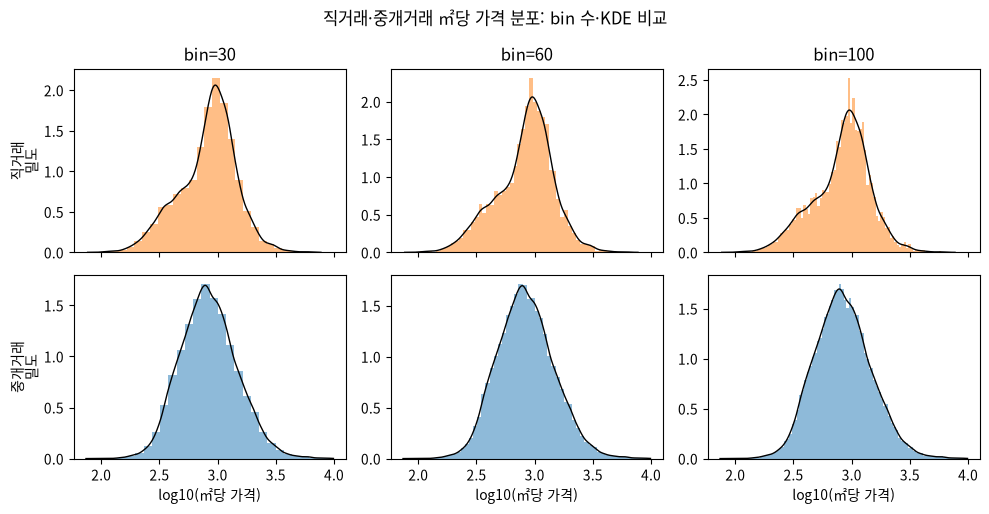

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5.2), dpi=100, sharex=True)
bin_counts = [30, 60, 100]
groups = [('직거래', direct_price), ('중개거래', brokered_price)]

for row, (name, s) in enumerate(groups):
    log_s = np.log10(s)
    kde = gaussian_kde(log_s)
    xs = np.linspace(log_s.min(), log_s.max(), 500)
    ys = kde(xs)
    for col, nbins in enumerate(bin_counts):
        ax = axes[row, col]
        ax.hist(log_s, bins=nbins, density=True, alpha=0.5, color='tab:orange' if name == '직거래' else 'tab:blue')
        ax.plot(xs, ys, color='black', linewidth=1)
        if row == 0:
            ax.set_title(f'bin={nbins}')
        if col == 0:
            ax.set_ylabel(f'{name}\n밀도')

for ax in axes[-1, :]:
    ax.set_xlabel('log10(㎡당 가격)')

fig.suptitle('직거래·중개거래 ㎡당 가격 분포: bin 수·KDE 비교')
fig.tight_layout()
fig.savefig('../results/figures/exp001_extra_peaks.png', dpi=100)
plt.show()
plt.close(fig)


## 추가 분석-2. 직거래 분해
이 셀에서 확인하는 질문: 직거래를 신축/비신축, EXP-001 하위 유형(분양 의심/저가 의심/기타)으로 나누면 원분포(㎡당 가격)가 어떻게 다른가?

신축/비신축은 전체 직거래 11,763건 기준(4-2의 age_bucket 사용). 하위 유형은 유효 셀 직거래 8,576건 기준(4-5의 direct_valid 재사용, subtype 열 포함).

In [11]:
direct_df_full = df[df['direct_flag'] == 1].copy()
direct_df_full['is_new'] = np.where(direct_df_full['age_bucket'] == '신축(0~2년)', '신축(0~2년)', '비신축')

new_vs_old_rows = []
for grp, sub in direct_df_full.groupby('is_new', observed=True):
    new_vs_old_rows.append({'구분': grp, '건수': len(sub), '㎡당가격 중앙값': sub['price_per_m2'].median()})
new_vs_old_table = pd.DataFrame(new_vs_old_rows)
print("신축/비신축 원분포 분해 (전체 직거래 11,763건 기준)")
print(new_vs_old_table.to_string(index=False))

subtype_rows = []
for grp, sub in direct_valid.groupby('subtype', observed=True):
    subtype_rows.append({'구분': grp, '건수': len(sub), '㎡당가격 중앙값': sub['price_per_m2'].median()})
subtype_raw_table = pd.DataFrame(subtype_rows)
print("\n하위 유형별 원분포 분해 (유효 셀 직거래 8,576건 기준)")
print(subtype_raw_table.to_string(index=False))


신축/비신축 원분포 분해 (전체 직거래 11,763건 기준)
      구분   건수    ㎡당가격 중앙값
     비신축 8266  756.093017
신축(0~2년) 3497 1108.319375

하위 유형별 원분포 분해 (유효 셀 직거래 8,576건 기준)
    구분   건수    ㎡당가격 중앙값
기타 직거래 6505  850.649351
 분양 의심  548 1285.327883
 저가 의심 1523  402.576490


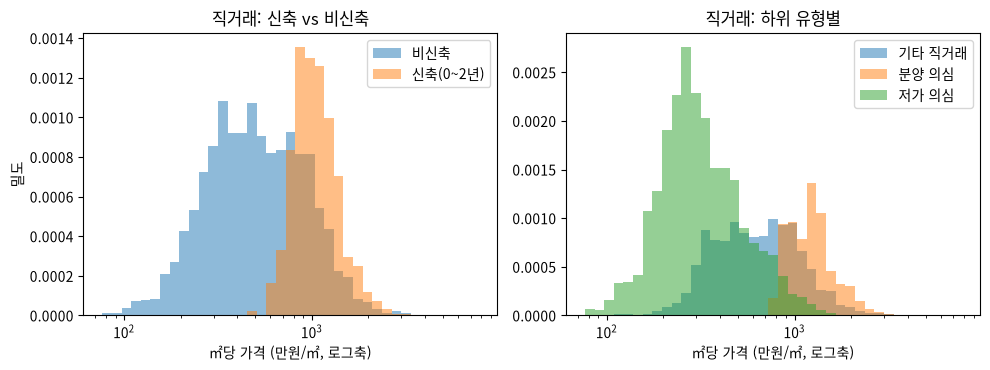

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), dpi=100)

ax = axes[0]
bins = np.logspace(np.log10(direct_price.min()), np.log10(direct_price.max()), 40)
for grp, sub in direct_df_full.groupby('is_new', observed=True):
    ax.hist(sub['price_per_m2'], bins=bins, alpha=0.5, density=True, label=grp)
ax.set_xscale('log')
ax.set_xlabel('㎡당 가격 (만원/㎡, 로그축)')
ax.set_ylabel('밀도')
ax.set_title('직거래: 신축 vs 비신축')
ax.legend()

ax = axes[1]
for grp, sub in direct_valid.groupby('subtype', observed=True):
    ax.hist(sub['price_per_m2'], bins=bins, alpha=0.5, density=True, label=grp)
ax.set_xscale('log')
ax.set_xlabel('㎡당 가격 (만원/㎡, 로그축)')
ax.set_title('직거래: 하위 유형별')
ax.legend()

fig.tight_layout()
fig.savefig('../results/figures/exp001_extra_subtype_dist.png', dpi=100)
plt.show()
plt.close(fig)


## 추가 분석-3. 구성 효과 확인
이 셀에서 확인하는 질문: 연식 구간별로 직거래 비율과 ㎡당 가격 수준이 함께 어떻게 다른가(구성 효과로 원분포가 왜곡될 수 있는가)?

In [13]:
def age_group_stats(g):
    return pd.Series({
        '거래건수': len(g),
        '직거래건수': int(g['direct_flag'].sum()),
        '직거래비율': g['direct_flag'].mean(),
        '㎡당가격 중앙값(전체)': g['price_per_m2'].median(),
        '㎡당가격 중앙값(직거래)': g.loc[g['direct_flag'] == 1, 'price_per_m2'].median(),
        '㎡당가격 중앙값(중개거래)': g.loc[g['direct_flag'] == 0, 'price_per_m2'].median(),
    })

age_composition_table = df.groupby('age_bucket', observed=True).apply(age_group_stats, include_groups=False).reset_index()
print("연식 구간별 직거래 비율과 ㎡당 가격 중앙값 (전체 69,371건 기준)")
print(age_composition_table.to_string(index=False))


연식 구간별 직거래 비율과 ㎡당 가격 중앙값 (전체 69,371건 기준)
age_bucket    거래건수  직거래건수    직거래비율  ㎡당가격 중앙값(전체)  ㎡당가격 중앙값(직거래)  ㎡당가격 중앙값(중개거래)
  신축(0~2년)  4658.0 3497.0 0.750751   1162.482806    1108.319375     1500.500167
     3~10년 22172.0 3632.0 0.163810   1033.307196     978.411077     1048.224984
    11~20년 13840.0 1282.0 0.092630    773.766827     699.301902      782.443460
    21년 이상 28701.0 3352.0 0.116790    604.075691     466.434646      623.321826


## 추가 분석-4. 반전 그림
이 셀에서 확인하는 질문: 원분포 중앙값 차이(%)와 조건 보정 상대가격 중앙값 차이(%)가 방향이 반대인가?

원분포 차이 = (직거래 ㎡당가격 중앙값 − 중개거래 ㎡당가격 중앙값) / 중개거래 중앙값 × 100. 조건보정 차이는 4-4·4-7의 상대가격 중앙값(셀 기준 보정값) 차이를 그대로 쓴다.

                비교    직거래 중앙값  중개거래 중앙값(기준)     차이(%)
         원분포(보정 전) 894.824708    821.624487  8.909206
조건 보정(법정동x연식x면적 셀)   0.911744      1.000000 -8.825579

방향 반전 여부: True (원분포 +8.9% vs 조건보정 -8.8%)


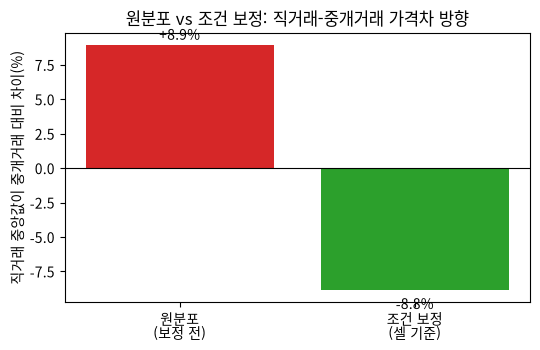

In [14]:
raw_direct_median = direct_price.median()
raw_brokered_median = brokered_price.median()
raw_diff_pct = (raw_direct_median - raw_brokered_median) / raw_brokered_median * 100

adj_brokered_median = float(summary_incl.loc[summary_incl['구분'] == '중개거래', '중앙값'].iloc[0])
adj_diff_pct = (direct_median - adj_brokered_median) / adj_brokered_median * 100

reversal_table = pd.DataFrame({
    '비교': ['원분포(보정 전)', '조건 보정(법정동x연식x면적 셀)'],
    '직거래 중앙값': [raw_direct_median, direct_median],
    '중개거래 중앙값(기준)': [raw_brokered_median, adj_brokered_median],
    '차이(%)': [raw_diff_pct, adj_diff_pct],
})
print(reversal_table.to_string(index=False))

direction_reversed = (raw_diff_pct > 0) != (adj_diff_pct > 0)
print(f"\n방향 반전 여부: {direction_reversed} (원분포 {raw_diff_pct:+.1f}% vs 조건보정 {adj_diff_pct:+.1f}%)")

fig, ax = plt.subplots(figsize=(5.5, 3.6), dpi=100)
labels = ['원분포\n(보정 전)', '조건 보정\n(셀 기준)']
values = [raw_diff_pct, adj_diff_pct]
colors = ['tab:red' if v > 0 else 'tab:green' for v in values]
bars = ax.bar(labels, values, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('직거래 중앙값이 중개거래 대비 차이(%)')
ax.set_title('원분포 vs 조건 보정: 직거래-중개거래 가격차 방향')
for bar, v in zip(bars, values):
    ax.annotate(f'{v:+.1f}%', (bar.get_x() + bar.get_width() / 2, v),
                textcoords='offset points', xytext=(0, 4 if v >= 0 else -14), ha='center')
fig.tight_layout()
fig.savefig('../results/figures/exp001_extra_reversal.png', dpi=100)
plt.show()
plt.close(fig)


## 추가 분석 요약

In [15]:
print("추가 분석 요약:")
print(f"1. 봉우리: 프로미넌스 10% 기준으로 직거래·중개거래 모두 bin 수·KDE에 관계없이 봉우리 1개로 안정적이다(두 봉우리는 bin=100의 인접 극댓값 노이즈로 보임).")
print(f"2. 구성 효과: 신축(0~2년) 거래는 직거래 비율이 75.1%로 매우 높고 가격 수준도 달라, 직거래 표본 구성이 원분포를 끌어올린다.")
print(f"3. 방향 반전: 원분포에서는 직거래 중앙값이 중개거래보다 {raw_diff_pct:+.1f}% 높지만, 법정동x연식x면적 셀로 보정하면 {adj_diff_pct:+.1f}%로 방향이 반대가 된다. EXP-001 판정(직거래 기본 제외)은 조건 보정 결과를 근거로 하며 변경하지 않는다.")


추가 분석 요약:
1. 봉우리: 프로미넌스 10% 기준으로 직거래·중개거래 모두 bin 수·KDE에 관계없이 봉우리 1개로 안정적이다(두 봉우리는 bin=100의 인접 극댓값 노이즈로 보임).
2. 구성 효과: 신축(0~2년) 거래는 직거래 비율이 75.1%로 매우 높고 가격 수준도 달라, 직거래 표본 구성이 원분포를 끌어올린다.
3. 방향 반전: 원분포에서는 직거래 중앙값이 중개거래보다 +8.9% 높지만, 법정동x연식x면적 셀로 보정하면 -8.8%로 방향이 반대가 된다. EXP-001 판정(직거래 기본 제외)은 조건 보정 결과를 근거로 하며 변경하지 않는다.
